In [35]:
# imports
import simpy
import numpy as np
import sys
import pandas as pd
import os
from IPython.display import Image
from tqdm import tqdm
import matplotlib.pyplot as plt
import time
sys.path.append('../code')
sys.path.append('../code/butools2/Python')

from sample_PH import *
# from single_station_PH import *
from butools.ph import *
from butools.fitting import *

<div dir="rtl">

## עד עכשיו לרוב השתמשנו בהתפלגות מעריכית לזמנים בין הגעות וזמני שירות. 
    
## זה היה רק מטעמי נוחות, מבחינה מעשית זה לא המציאות.
    
## כאשר אנחנו מדברים על התפלגות זמני שירות או בין הגעות, אז אנחנו נמצאים בהתפלגות רציפה ואי שלילית. 
    
## כמובן התפלגות מעריכית היא דוגמא טוב לכך אבל יש עוד הרבה
    
## להלן כמה דוגמאות:
    


## * Gamma 
## * Weibull
## * Chi-square
## * PH

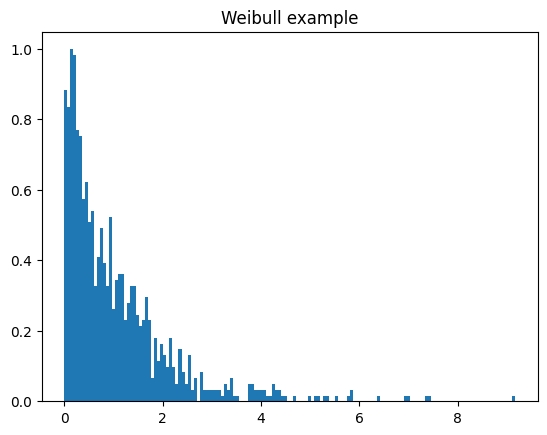

In [4]:
s = np.random.weibull(1., 1000)

plt.figure()
plt.hist(s, density = True, bins = 150)
plt.title('Weibull example')

plt.show()

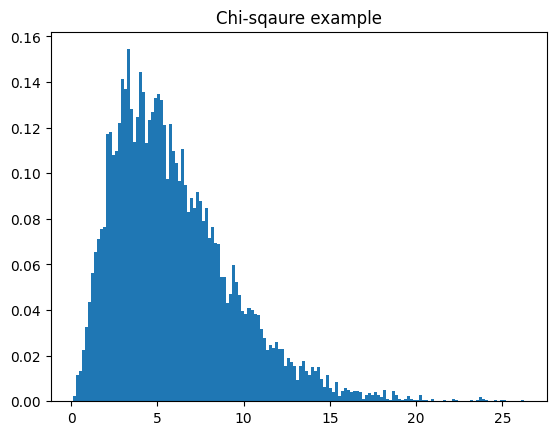

In [5]:
s = np.random.chisquare(6., 10000)
plt.figure()
plt.hist(s, density = True, bins = 150)
plt.title('Chi-sqaure example')
plt.show()

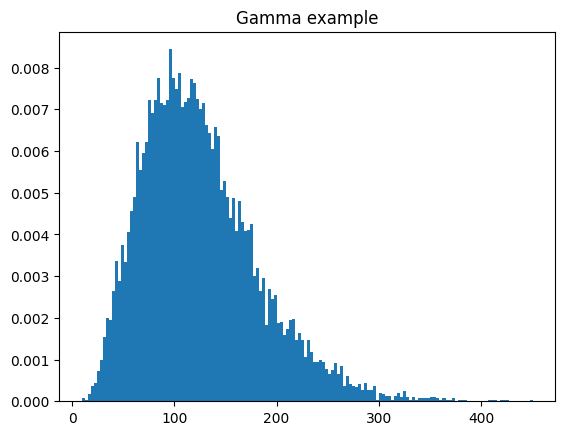

In [6]:
s = np.random.gamma(5., 25, 10000)

plt.figure()
plt.hist(s, density = True, bins = 150)
plt.title('Gamma example')
plt.show()

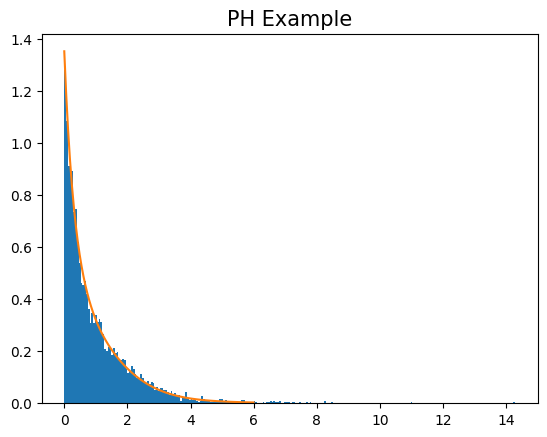

In [5]:
a, S ,moms, PH_samples = sample(5000, 75)
x_vals  = np.linspace(0,6,100)
y_vals = compute_pdf_within_range(x_vals, a, S)


plt.figure()
plt.hist(PH_samples, density = True, bins = 250)
plt.plot(x_vals, y_vals)
plt.title('PH Example', fontsize= 15)
plt.show()

In [6]:
s = np.random.gamma(3., 0.5,10000000)

s.mean()

1.499974053258482

<div dir="rtl">

## בשביל להשתמש בהם בסימלוציה פשוט נחליף את השורה שאיתה אנחנו מסמלצים את זמני ההגעה ושירות
    
### למשל נניח שנשתמש בהתפלגות Gamma
    
### ההתפלגות מקבלת שני פרמטרים:    $k$, $\theta$   
    
    
## $$ X \sim Gamma(k, \theta) $$
    
## $$ E[X] =  k \theta $$

## $$ Var[X] =  k \theta^2 $$

    

In [7]:
## Model input

k_arrival = 1
theta_arrival = 3
k_service = 1
theta_service = 2
end_time = 25

In [8]:
#########################################################
###################  Arrival block ###################### 
#########################################################
                
def customer_arrivals(env):
    
    id_customer = 0
    
    while True:
        
        id_customer += 1
        
        # Timeout means the time span bewteen two arrivals
        yield env.timeout(np.random.gamma(k_arrival, theta_arrival))
        
        print('Customer {} arrived at time: {}' .format(id_customer, env.now))

        env.process(service(env, id_customer))

#########################################################
###################  Service block ###################### 
#########################################################

def service(env, id_customer):

    ## For tracking the arrival time of customer
    arrival_time = env.now

    with nurse.request() as req:
        
        ## Requesting a server
        yield req
        print('Customer {} start service  at time: {}' .format(id_customer, env.now))
        # if server if available service will be granted.
        
        # Timeout means the time span bewteen a single service
        yield env.timeout(np.random.gamma(k_service, theta_service))
        
        print('Customer {} complete service  at time: {}' .format(id_customer, env.now))



#########################################################
#################  Initiate system ###################### 
#########################################################        

# Defining a simpy envirment
env = simpy.Environment()
# Attaching a server to a simpy envirment
nurse = simpy.Resource(env, capacity=1)

# Initializing an arrival process
env.process(customer_arrivals(env))

# Activating the system
env.run(until=end_time)

Customer 1 arrived at time: 0.5180055824634363
Customer 1 start service  at time: 0.5180055824634363
Customer 2 arrived at time: 1.128146619685975
Customer 1 complete service  at time: 1.2100824578130935
Customer 2 start service  at time: 1.2100824578130935
Customer 2 complete service  at time: 1.73998028286581
Customer 3 arrived at time: 1.7906432108555288
Customer 3 start service  at time: 1.7906432108555288
Customer 3 complete service  at time: 3.759343668359265
Customer 4 arrived at time: 7.871722887061016
Customer 4 start service  at time: 7.871722887061016
Customer 4 complete service  at time: 10.922449580086019
Customer 5 arrived at time: 11.872070773680218
Customer 5 start service  at time: 11.872070773680218
Customer 5 complete service  at time: 12.729053606529689
Customer 6 arrived at time: 20.442094845814722
Customer 6 start service  at time: 20.442094845814722
Customer 6 complete service  at time: 20.843232469871676
Customer 7 arrived at time: 22.793624329265203
Customer 7 

<div dir="rtl">

    
### כאשר מנתחים מערכת תורים לא יודעים מראש מה התפלגות זמנים בין הגעות או זמני שירות. במקום, יש eventlog שמתאר מה היה במערכת. באותו event log אנחנו יודעים מתי צרכנים הגיעו לתור, נכנסנו לשירות וסיימו שירות. בנוסף אנחנו יודעים עוד פרטים על הלקוחות. למשל, בשירות רפואי יודעים גיל, מגדר או סיבה להגעה. 
    
### במערכות האלו היו רוצים לדעת what if questions.
    
### מה אם היינו מכניסים עוד שרת? מה אם קצב ההגעה היה גדל פי 2? 
    
### בשביל לענות על השאלה הזאת - נרצה קודם לדעת מה קורה במצב הנוכחי. 
    
### רק אחרי זה נוכל לשנות את הפרמטר המיועד. 
    
### נתחיל בדוגמה פשוטה.
    
### להלן מערכת תורים עם שני סוגים של צרכנים. סוג אחד מתייחס לצרכנים VIP ואילו סוג שני צרכנים רגילים. 
    
### נרצה לבדוק מה התפלגות זמני שירות של כל זוג צרכן והאם הם בכלל שונים. 
    
### להלן הevent log: 

In [9]:
df = pkl.load(open('../pkls/df_two_type_service.pkl', 'rb'))

In [10]:
df.head(15)

,Event,Time,Customer,Customer type,Queue lenght,System lenght
0,Arrival,0.675404,1,2,0,1
1,Enter service,0.675404,1,2,0,1
2,Departure,0.912713,1,2,0,0
3,Arrival,2.470509,2,2,0,1
4,Enter service,2.470509,2,2,0,1
5,Arrival,3.354646,3,1,1,2
6,Departure,3.632326,2,2,1,1
7,Enter service,3.632326,3,1,0,1
8,Departure,4.368320,3,1,0,0
9,Arrival,6.133678,4,2,0,1


<div dir="rtl">

    
### ננסה לחלץ זמני שירות בכל אחד מהסוגים: 

In [11]:
df_type1 = df.loc[df['Customer type']==1, :]

In [12]:
customers = df_type1['Customer'].unique()
customers[:10]

array([ 3,  5,  6,  7,  9, 12, 14, 17, 19, 20], dtype=int64)

In [42]:
customers.shape

(1644,)

In [13]:
customer = customers[0]
curr_df = df_type1.loc[df_type1['Customer']==customer, :]
curr_df.head()

,Event,Time,Customer,Customer type,Queue lenght,System lenght
5,Arrival,3.354646,3,1,1,2
7,Enter service,3.632326,3,1,0,1
8,Departure,4.368320,3,1,0,0


In [14]:
enter_service = curr_df.loc[curr_df['Event']=='Enter service', 'Time'].item()
complete_service = curr_df.loc[curr_df['Event']=='Departure', 'Time'].item()
service_time = complete_service - enter_service
service_time


0.735994176647556

In [15]:
service_times_type_1 = []

for customer in df_type1['Customer'].unique():
    
    try:
        curr_df = df_type1.loc[df_type1['Customer']==customer, :]

        enter_service = curr_df.loc[curr_df['Event']=='Enter service', 'Time'].item()
        complete_service = curr_df.loc[curr_df['Event']=='Departure', 'Time'].item()

        service_time = complete_service - enter_service

        service_times_type_1.append(service_time)
    except:
        print('Customer not departed yet')

In [16]:
len(service_times_type_1)

1644

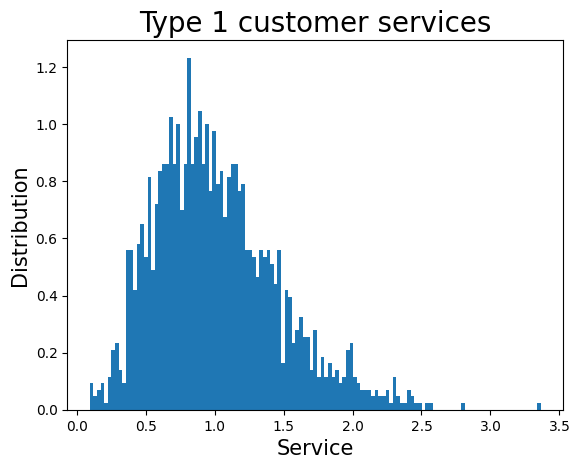

In [17]:
plt.figure()
plt.hist(service_times_type_1, density = True, bins = 125)
plt.title('Type 1 customer services', fontsize = 20)
plt.xlabel('Service', fontsize = 15)
plt.ylabel('Distribution', fontsize = 15)
plt.show()

In [18]:
df_type2 = df.loc[df['Customer type']==2, :]

service_times_type_2 = []

for customer in tqdm(df_type2['Customer'].unique()):
    curr_df = df_type2.loc[df_type2['Customer']==customer, :]
    try:
        enter_service = curr_df.loc[curr_df['Event']=='Enter service', 'Time'].item()
        complete_service = curr_df.loc[curr_df['Event']=='Departure', 'Time'].item()

        service_time = complete_service - enter_service

        service_times_type_2.append(service_time)
    except:
        print('customer not departed yet')

100%|█████████████████████████████████████████████████████████████████████████████| 3896/3896 [00:05<00:00, 729.99it/s]

customer not departed yet
customer not departed yet


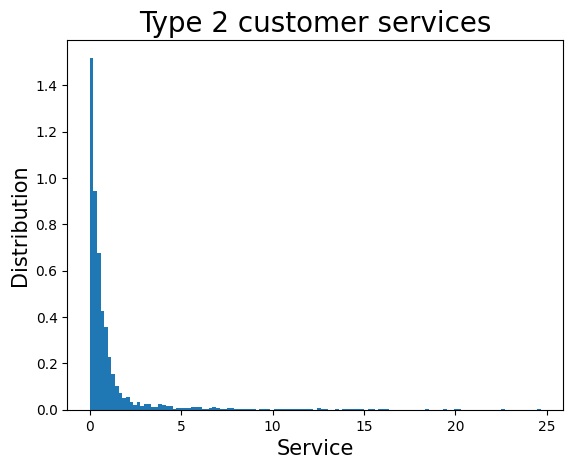

In [19]:
plt.figure()
plt.hist(service_times_type_2, density = True, bins = 125)
plt.title('Type 2 customer services', fontsize = 20)
plt.xlabel('Service', fontsize = 15)
plt.ylabel('Distribution', fontsize = 15)
plt.show()

In [20]:
np.array(service_times_type_1).mean(), np.array(service_times_type_2).mean()

(1.0145714639937042, 1.0364115498913828)

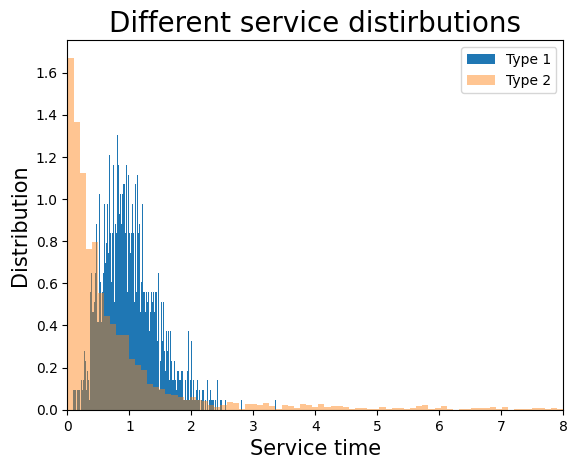

In [21]:
plt.figure()
plt.hist(service_times_type_1, density = True, bins = 250, label = 'Type 1')
plt.hist(service_times_type_2, density = True, bins = 250, alpha = 0.45, label = 'Type 2')
plt.xlim(0,8)
plt.title('Different service distirbutions', fontsize = 20)
plt.legend()
plt.xlabel('Service time',  fontsize = 15)
plt.ylabel('Distribution', fontsize = 15)
plt.show()

<div dir="rtl">

###  נראה כי יש הבדל ניכר בהתפלגות של שני הסוגים

<div dir="rtl">


## עכשיו נרצה למשל לדעת מה יקרה למערכת אם נתייחס לכל הצרכנים כאל VIP? מה זה יעשה למשל לזמני שהייה במערכת?
    
### בשביל לענות על זה נעשה פעמיים סימלוציה. פעם אחת ללא השינוי בשביל לדעת מה המצב הקיים

### פעם שנייה נבדוק מה קורה למערכת אחרי השינוי.
    
### סימולציה של מצב קיים. תחילה נמצא את התפלגות של זמן שירות עבור כל קבוצה. נמצא את הPH הכי קרוב. 
    




Runtime for 5 is 0.10606908798217773


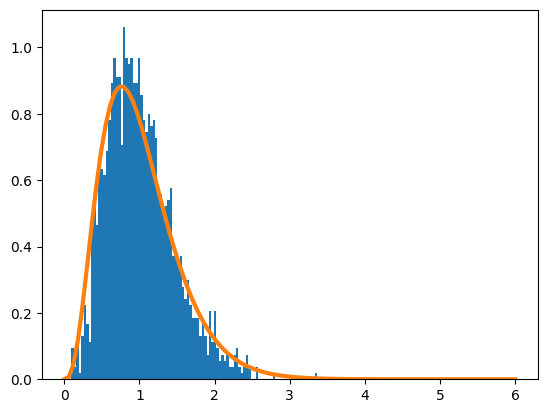

Runtime for 10 is 1.908717393875122


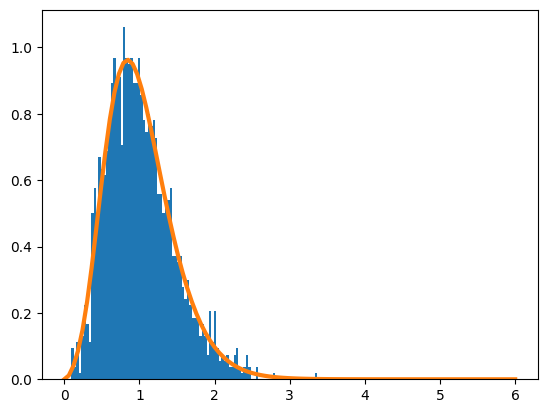

Runtime for 15 is 14.946718692779541


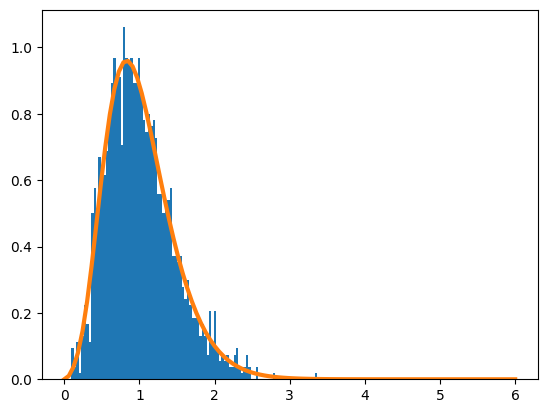

In [22]:
for size in [5,10,15]:
    begin = time.time()
    res_EM = PHFromTrace(np.array(service_times_type_1), size)

    x_vals  = np.linspace(0,6,100)
    a_EM = np.array(res_EM[0]).flatten()
    S_EM = np.array(res_EM[1])
    
    end = time.time()
    print('Runtime for {} is {}' .format(size, end-begin))
    y_vals = compute_pdf_within_range(x_vals, a_EM, S_EM)

    plt.figure()
    plt.hist(service_times_type_1, density = True, bins = 100)
    plt.plot(x_vals, y_vals, lw = 3)
    plt.show()

In [51]:
res_EM[0].shape

(1, 15)

In [50]:
res_EM[1].shape

(15, 15)

In [23]:
a_EM1, S_EM1 = a_EM, S_EM

<div dir="rtl"> 

###  נמצא עבור צרכן type 2

Runtime for 5 is 0.3377196788787842


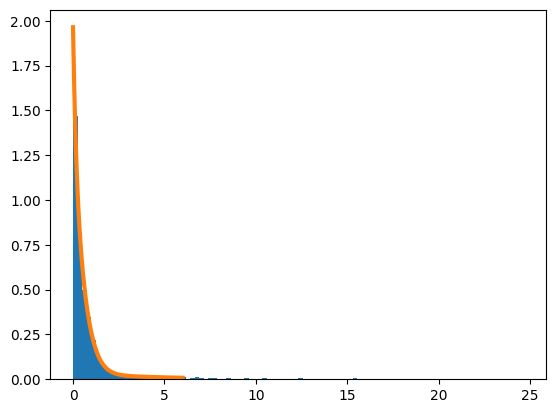

Runtime for 10 is 5.575208425521851


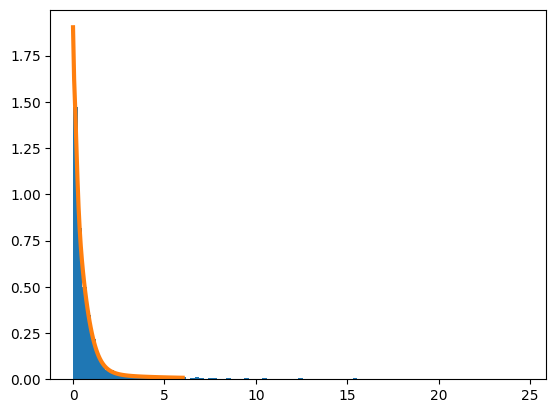

Runtime for 15 is 34.947683572769165


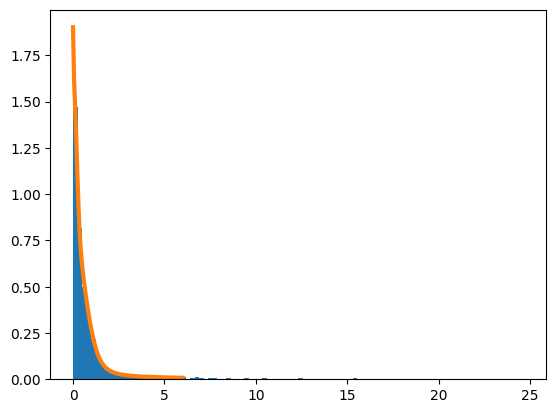

In [24]:
for size in [5,10,15]:
    begin = time.time()
    res_EM = PHFromTrace(np.array(service_times_type_2), size)
    x_vals  = np.linspace(0,6,100)
    a_EM = np.array(res_EM[0]).flatten()
    S_EM = np.array(res_EM[1])
    
    end = time.time()
    print('Runtime for {} is {}' .format(size, end-begin))
    
    y_vals = compute_pdf_within_range(x_vals, a_EM, S_EM)

    plt.figure()
    plt.hist(service_times_type_2, density = True, bins = 100)
    plt.plot(x_vals, y_vals, lw = 3)
    plt.show()

In [25]:
a_EM2, S_EM2 = a_EM, S_EM

<div dir="rtl"> 

### נגריל הרבה ערכים מאותן התפלגויות כך שיהיו מוכנות לסימולציה

In [26]:
start = time.time()
services1 = SamplesFromPH(ml.matrix(a_EM1), S_EM1, 900000)
services2 = SamplesFromPH(ml.matrix(a_EM2), S_EM2, 900000)
end = time.time()
print(end - start)

96.78864812850952


In [27]:
services_ = {1: services1, 2: services2}

services_[1].mean()

1.014553316110852

In [28]:
services_[2].mean()

1.036732357432619

In [41]:
## Defining a new class: of customers
class Customer:
    def __init__(self, p_id, arrival_time, type_cust):
        self.id = p_id
        self.arrival_time = arrival_time
        self.type = type_cust


class Queue_single_station:

    def __init__(self, lamda, services, sim_time, df_event_track = False):
        
        ################################
        self.env = simpy.Environment()  # initializing simpy enviroment
        self.end_time = sim_time  # The time simulation terminate
        self.df_waiting_times = pd.DataFrame([])  # is a dataframe the holds all information waiting time
        self.services = services  # service rate
        self.lamda = lamda  # inter-arrival rate
        ####################################
        
        ########################################
        self.server = simpy.Resource(self.env, capacity=1)  # Defining a resource with capacity 1
        self.env.process(self.customer_arrivals())  ## Initializing a process
        ##########################################
        
        
        self.df_events = pd.DataFrame([])  # is a dataframe the holds all information of the queue dynamic:
        # an event can one of three: (1. arrival, 2. entering service 3. service completion)     
        self.waiting_times= []
        self.df_event_track = df_event_track
        self.num_cust_durations = np.zeros(500)  ## the time duration of each each state (state= number of cusotmers in the system)
        self.last_event_time = 0  # the time of the last event -
        self.num_cust_sys = 0  # keeping track of number of customers in the system
        self.id_current = 1  # keeping track of cusotmers id

    

    def update_new_row(self, customer, event):

        new_row = {'Event': event, 'Time': self.env.now, 'Customer': customer.id,'Customer type': customer.type,
                   'Queue lenght': len(self.server.queue), 'System lenght': self.num_cust_sys}

        self.df_events = pd.concat([self.df_events, pd.DataFrame([new_row])], ignore_index=True)

    #########################################################
    ################# Service block #########################
    #########################################################

    def service(self, customer):
        
        with self.server.request() as req:
            # Updating the a new cusotmer arrived
            if self.df_event_track:
                self.update_new_row(customer, 'Arrival')

            yield req

            if self.df_event_track:
            # Updating the a new cusotmer entered service
                self.update_new_row(customer, 'Enter service')
            
            ind_ser = np.random.randint(self.services[customer.type].shape[0])
            yield self.env.timeout(self.services[customer.type][ind_ser])

            tot_time = self.env.now - self.last_event_time  # keeping track of the last event
            self.num_cust_durations[self.num_cust_sys] += tot_time  # Since the number of customers in the system changes
            # we compute how much time the system had this number of customers

            self.num_cust_sys -= 1  # updating number of cusotmers in the system
            self.last_event_time = self.env.now

            # Updating the a cusotmer departed the system
            if self.df_event_track:
                self.update_new_row(customer, 'Departure')

            if is_print:
                print('Departed customer {} at {}'.format(customer.id, self.env.now))

            self.waiting_times.append(self.env.now - customer.arrival_time)

    #########################################################
    ################# Arrival block #########################
    #########################################################

    def customer_arrivals(self):

        
        while True:

            yield self.env.timeout(np.random.exponential(1 / self.lamda))
            
            random_0_1 = np.random.rand()
        
            if random_0_1< 0.3:

                cust_type = 1

            else:
                cust_type = 2
            
            tot_time = self.env.now - self.last_event_time
            self.num_cust_durations[self.num_cust_sys] += tot_time
            self.num_cust_sys += 1
            self.last_event_time = self.env.now
            self.last_time = self.env.now

            curr_id = self.id_current
            arrival_time = self.env.now
            customer = Customer(curr_id, arrival_time, cust_type)

            self.id_current += 1

            if is_print:
                print('Arrived customer {} at {}'.format(customer.id, self.env.now))

            self.env.process(self.service(customer))

    def get_steady_single_station(self):
        return self.num_cust_durations / self.num_cust_durations.sum()

    
    def run(self):
        self.env.run(until=self.end_time)  ## Running the simulaiton until self.end_time


In [ ]:
services_ = {1: services1, 2: services2}
lamda  = 0.7
queue_single_station = Queue_single_station(lamda, services_, 80000, True)
queue_single_station.run()


dist_L_existing = queue_single_station.get_steady_single_station()[:20]

<div dir="rtl">

### עכשיו נחשב עבור המקרה שבו כל הצרכנים מאותו סוג

In [40]:
services1.mean()

1.014553316110852

In [43]:

# Notice all services are type 1

services_a = {1: services1, 2: services1}
lamda = 0.7
queue_single_station1 = Queue_single_station(lamda, services_a, 80000, True)
queue_single_station1.run()

In [46]:
dist_L_existing = queue_single_station.get_steady_single_station()
dist_L_VIP_only = queue_single_station1.get_steady_single_station()


## If you wish to skip the simulation

In [48]:
dist_L_existing, dist_L_VIP_only = pkl.load(open('../pkls/L_dist.pkl', 'rb'))

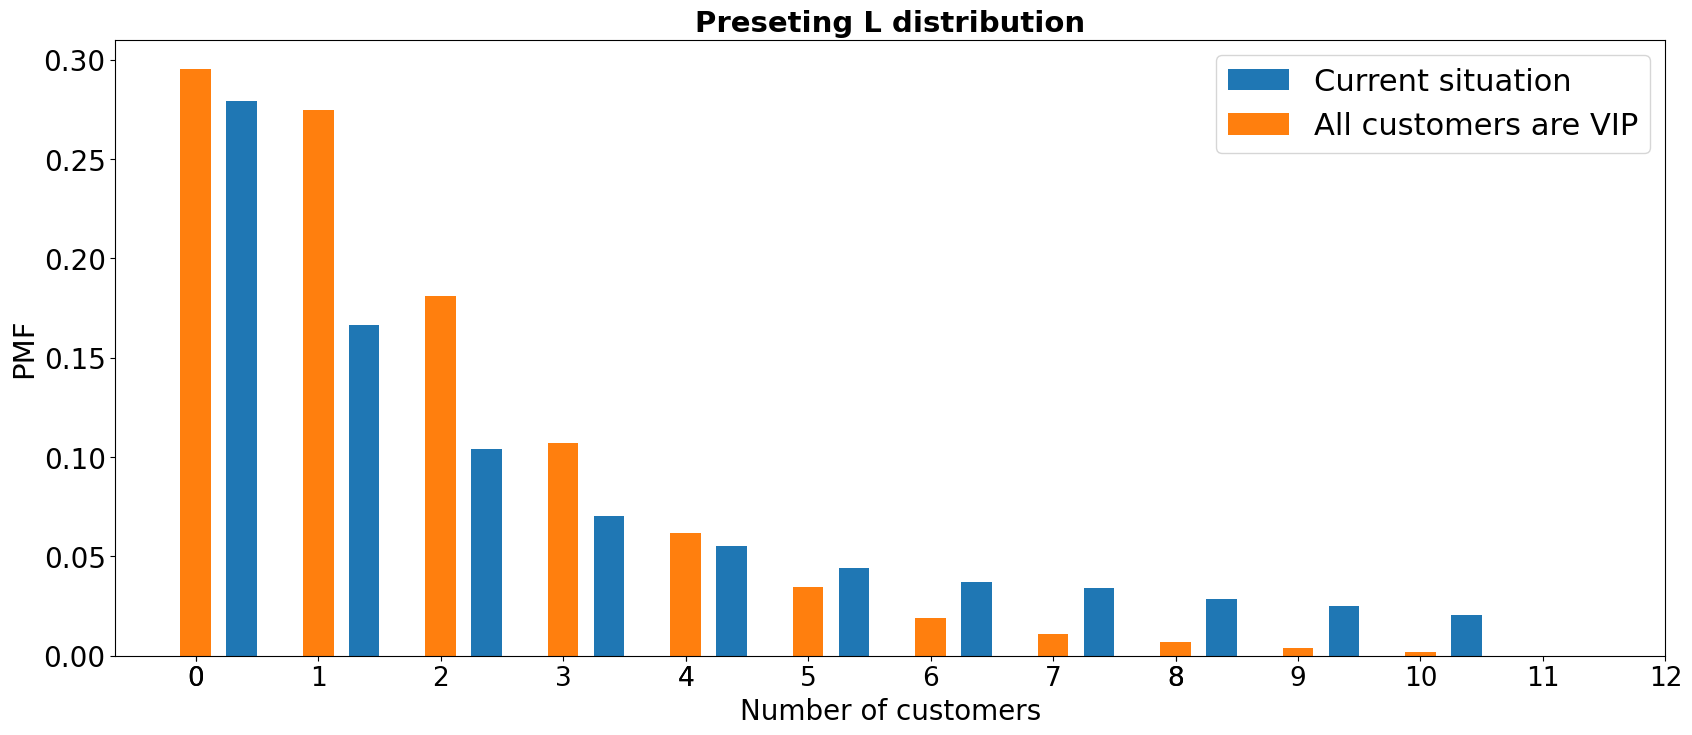

In [49]:
## Plotting the graph

fig, (ax1) = plt.subplots(1, 1, figsize=(20, 8))
width = 0.25
max_probs = 11
rects1 = ax1.bar(1.5*width+np.arange(max_probs), dist_L_existing[:11], width, label='Current situation')
rects2 = ax1.bar(np.arange(max_probs) , dist_L_VIP_only[:11], width, label='All customers are VIP')
plt.rcParams['font.size'] = '20'

# # Add some text for labels, title and custom x-axis tick labels, etc.
ax1.set_ylabel('PMF', fontsize=21)
ax1.set_xlabel('Number of customers', fontsize=20)
ax1.set_title( 'Preseting L distribution' , fontsize=21, fontweight="bold")
ax1.set_xticks(np.linspace(0,12,16).astype(int))
ax1.set_xticklabels(np.linspace(0,12,16).astype(int), fontsize=19)
ax1.legend(fontsize=22)
plt.show()

In [23]:
(dist_L_existing*np.arange(dist_L_existing.shape[0])).sum()

4.438569196026924

In [24]:
(dist_L_VIP_only*np.arange(dist_L_VIP_only.shape[0])).sum()

1.7131477575477585

<div dir="rtl">

## נראה שלעבור לכך שכולם יהיו VIP יוריד את תוחלת אורך התור מ4.43 ל1.713

## Littel's law

## $$ \lambda E[S] = E[L] $$